In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import scienceplots
import pywt
plt.style.use(['science','ieee'])

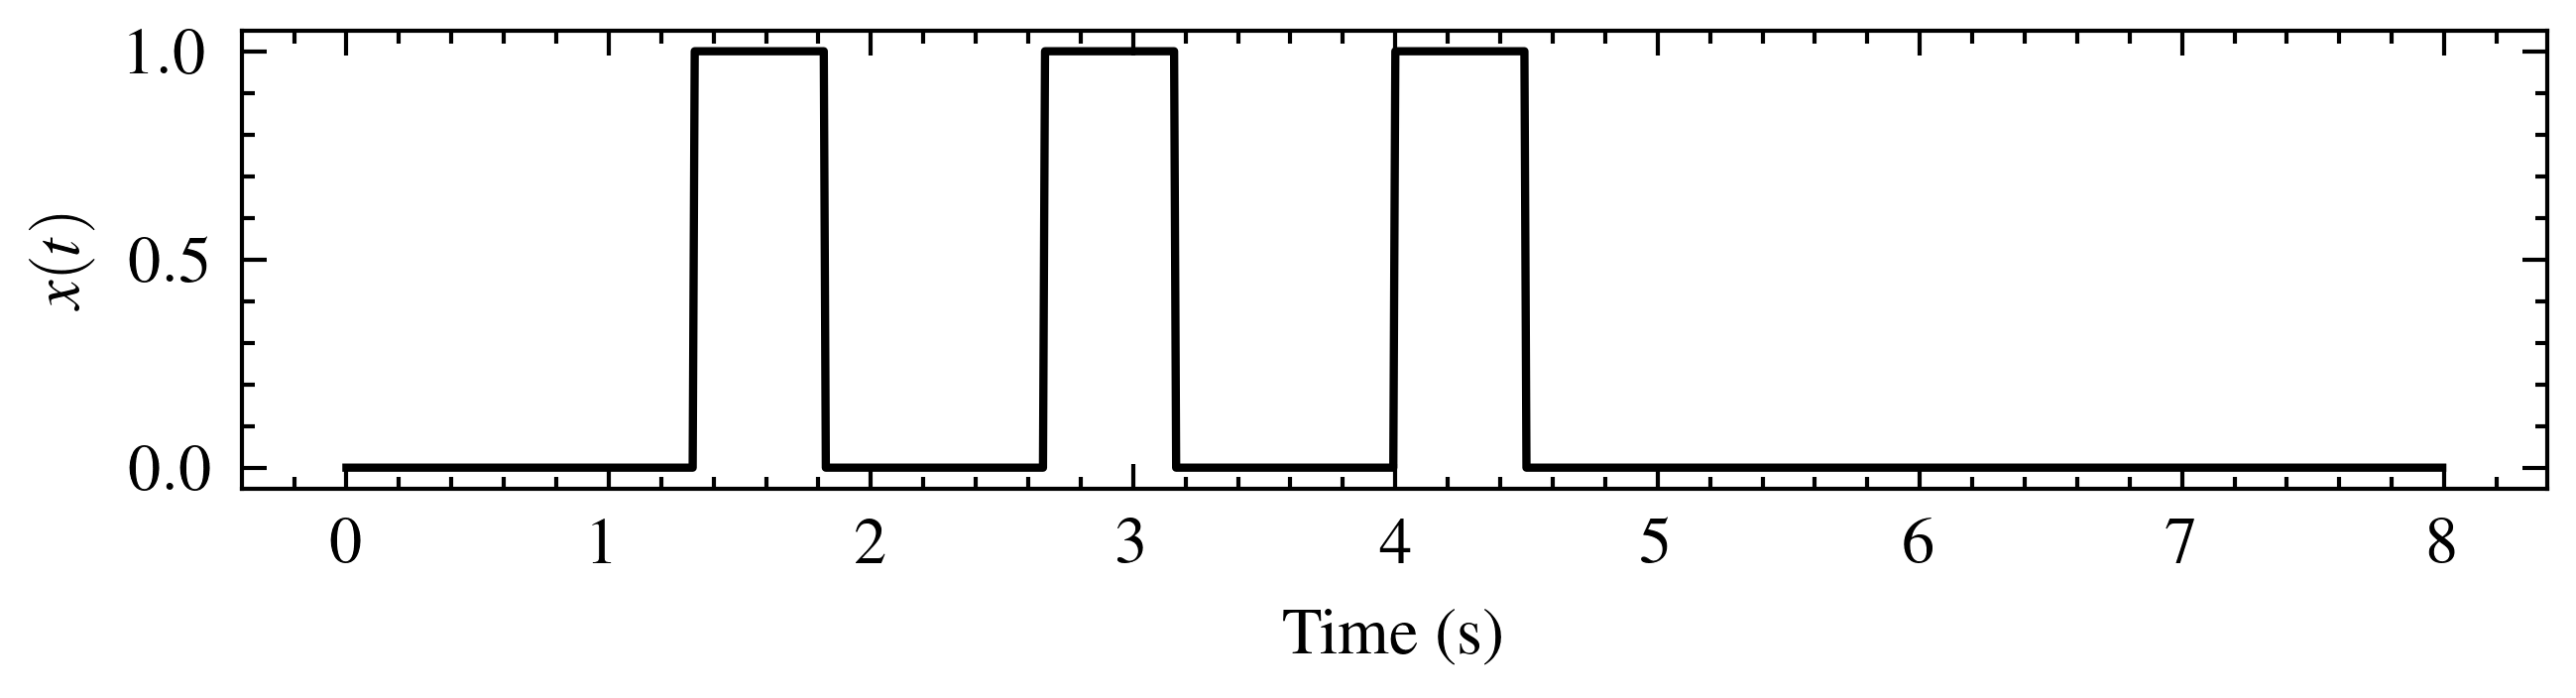

In [3]:
T = 8
fs = 128
dt = 1/fs
t = np.arange(0,T,dt)
n = len(t)

x = np.zeros(n)
x[n//6 : n//6 + int(0.5//dt)] = 1
x[n//3 : n//3 + int(0.5//dt)] = 1
x[n//2 : n//2 + int(0.5//dt)] = 1

plt.figure(figsize=(5,1))
plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("$x(t)$")
plt.savefig(f"figures_wavelet/example_pulses.png", dpi=300)

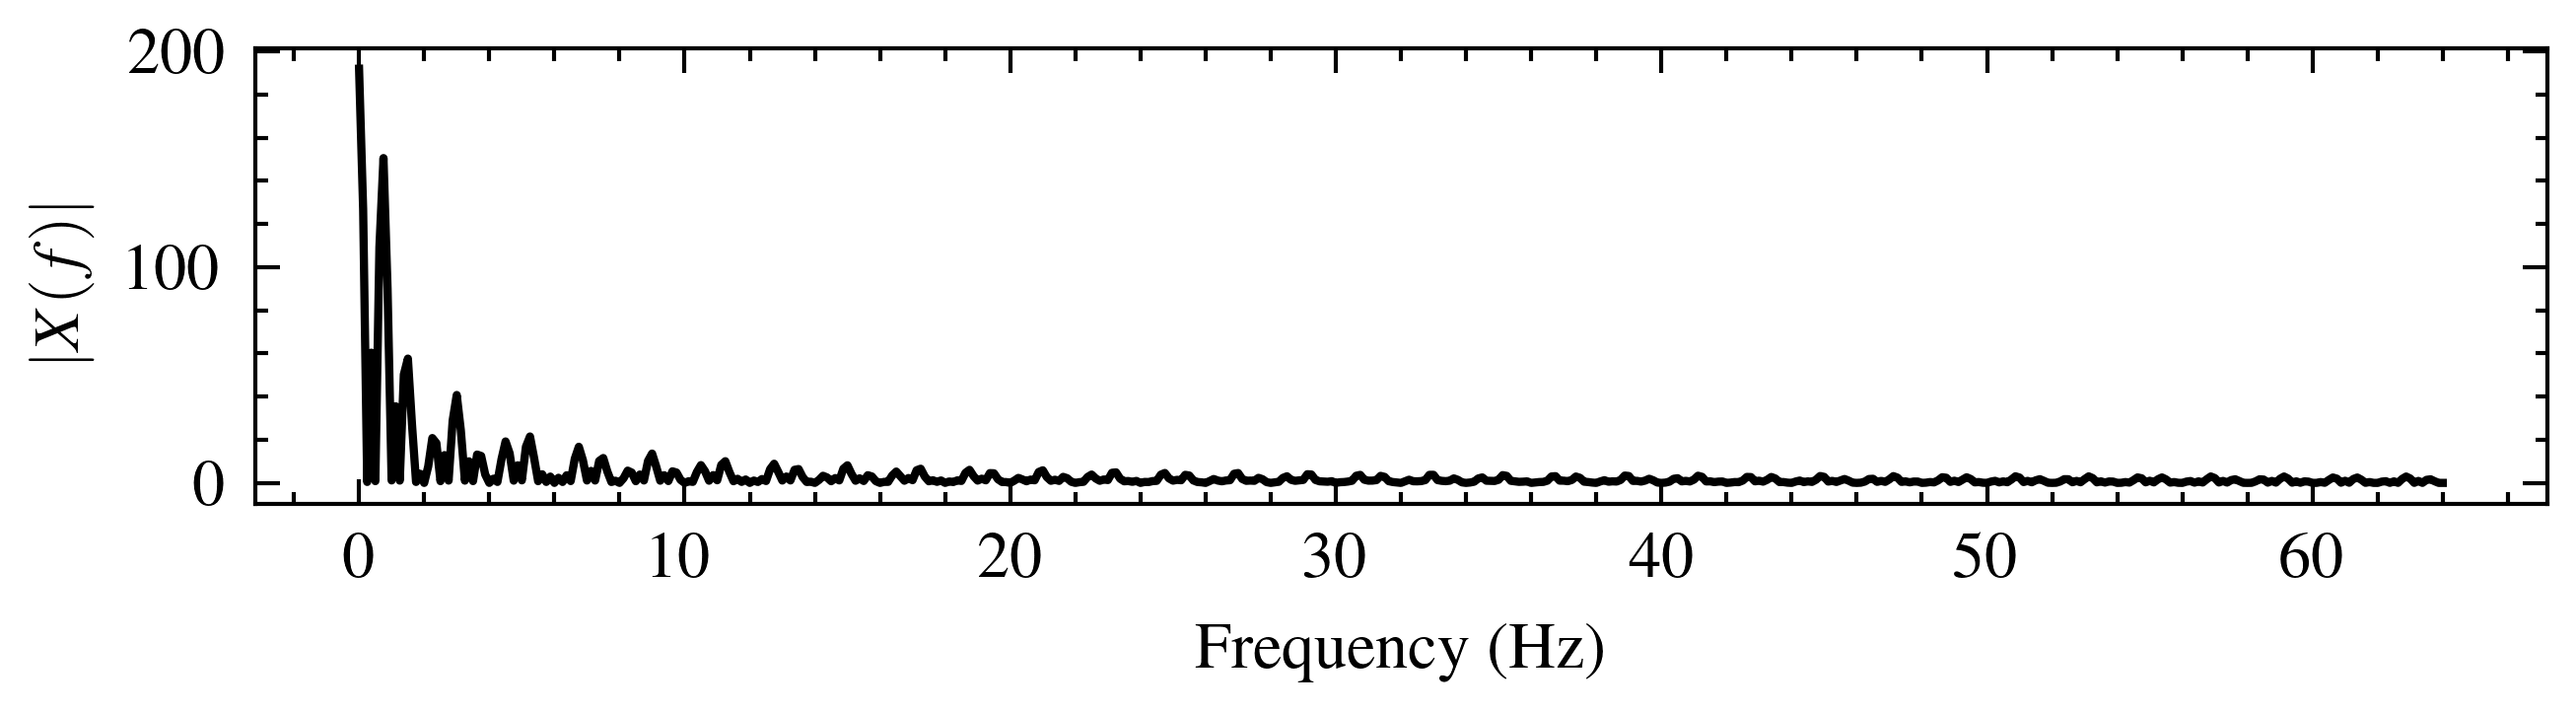

In [4]:
X = np.fft.rfft(x)
f = np.fft.rfftfreq(n, dt)

plt.figure(figsize=(5,1))
plt.plot(f, np.abs(X))
plt.xlabel("Frequency (Hz)")
plt.ylabel("$|X(f)|$")
plt.savefig(f"figures_wavelet/example_pulses_fft.png", dpi=300)

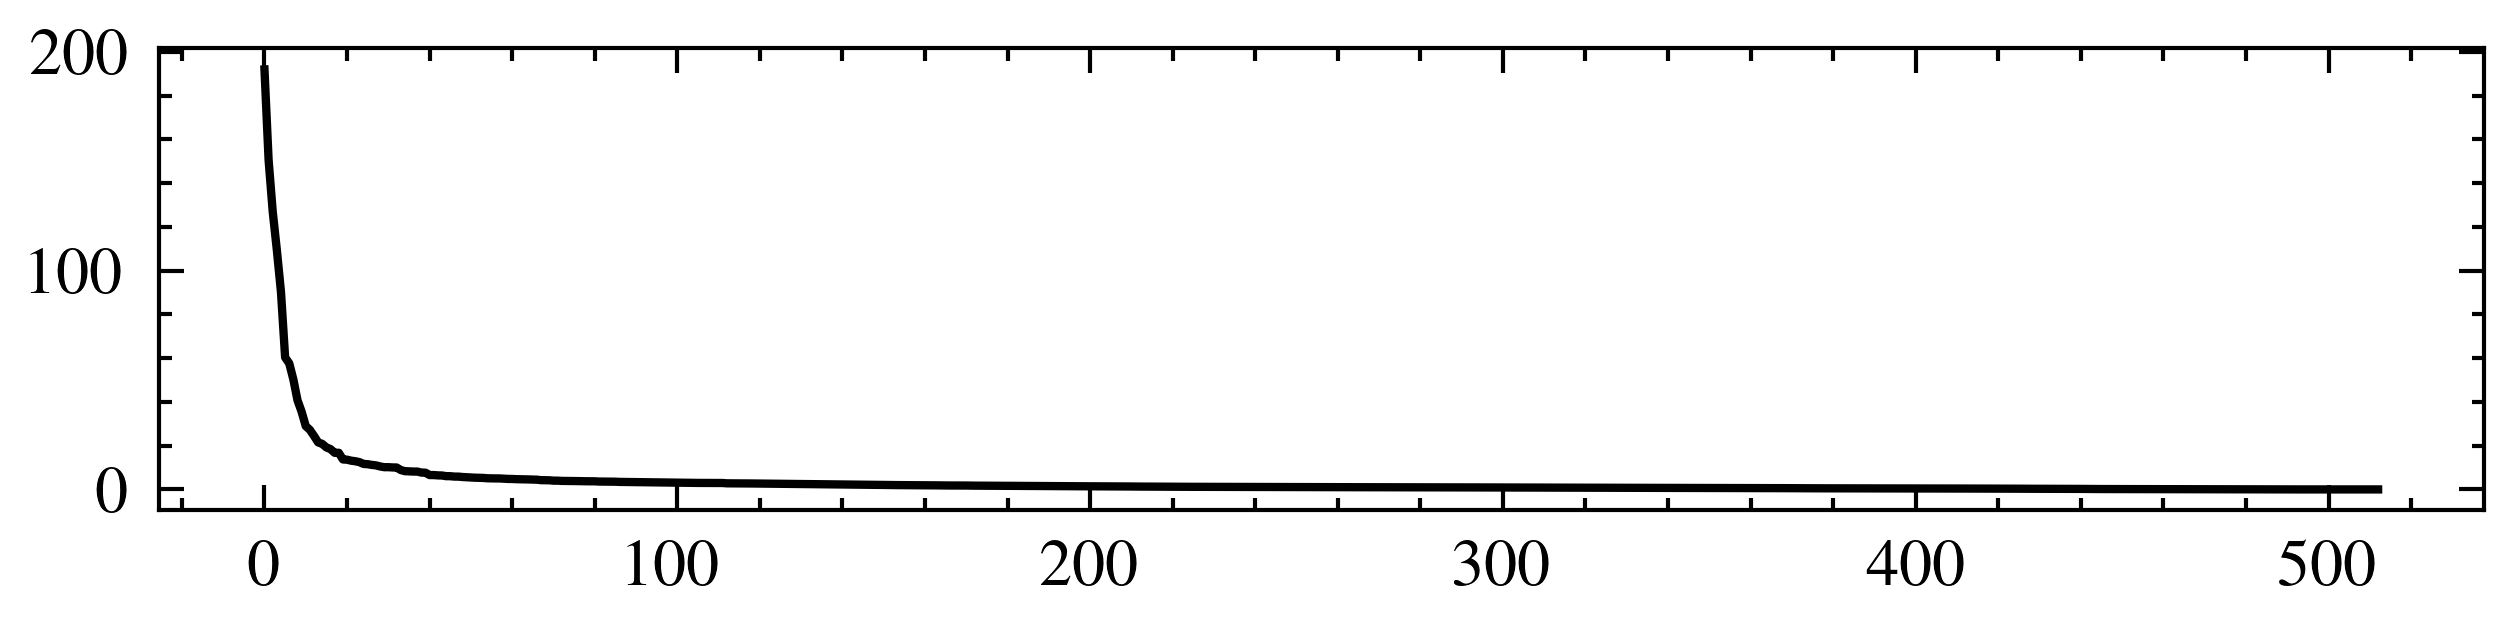

In [5]:
plt.figure(figsize=(5,1))
plt.plot(np.sort(np.abs(X))[::-1])

In [6]:
def mexhat(t):
    return (2/np.pi**(1/4)) * (1 - t**2) * np.exp(-(t**2)/2)

In [7]:
def mexhat_psi_freq(w):
    return ((-np.sqrt(8)*np.pi**(1/4))/np.sqrt(3)) * w**2 * np.exp(-(w**2)/2)

def mexhat_phi_freq(w):
    return ((2*np.pi**(1/4))/np.sqrt(3)) * np.sqrt(w**2 + 1) * np.exp(-(w**2)/2)

In [8]:
m_t = np.arange(-6, 6, 0.1)
m = [mexhat(tt) for tt in m_t]

u = 2
s = 0.5
m_us = [mexhat((tt-u)/s) for tt in m_t]

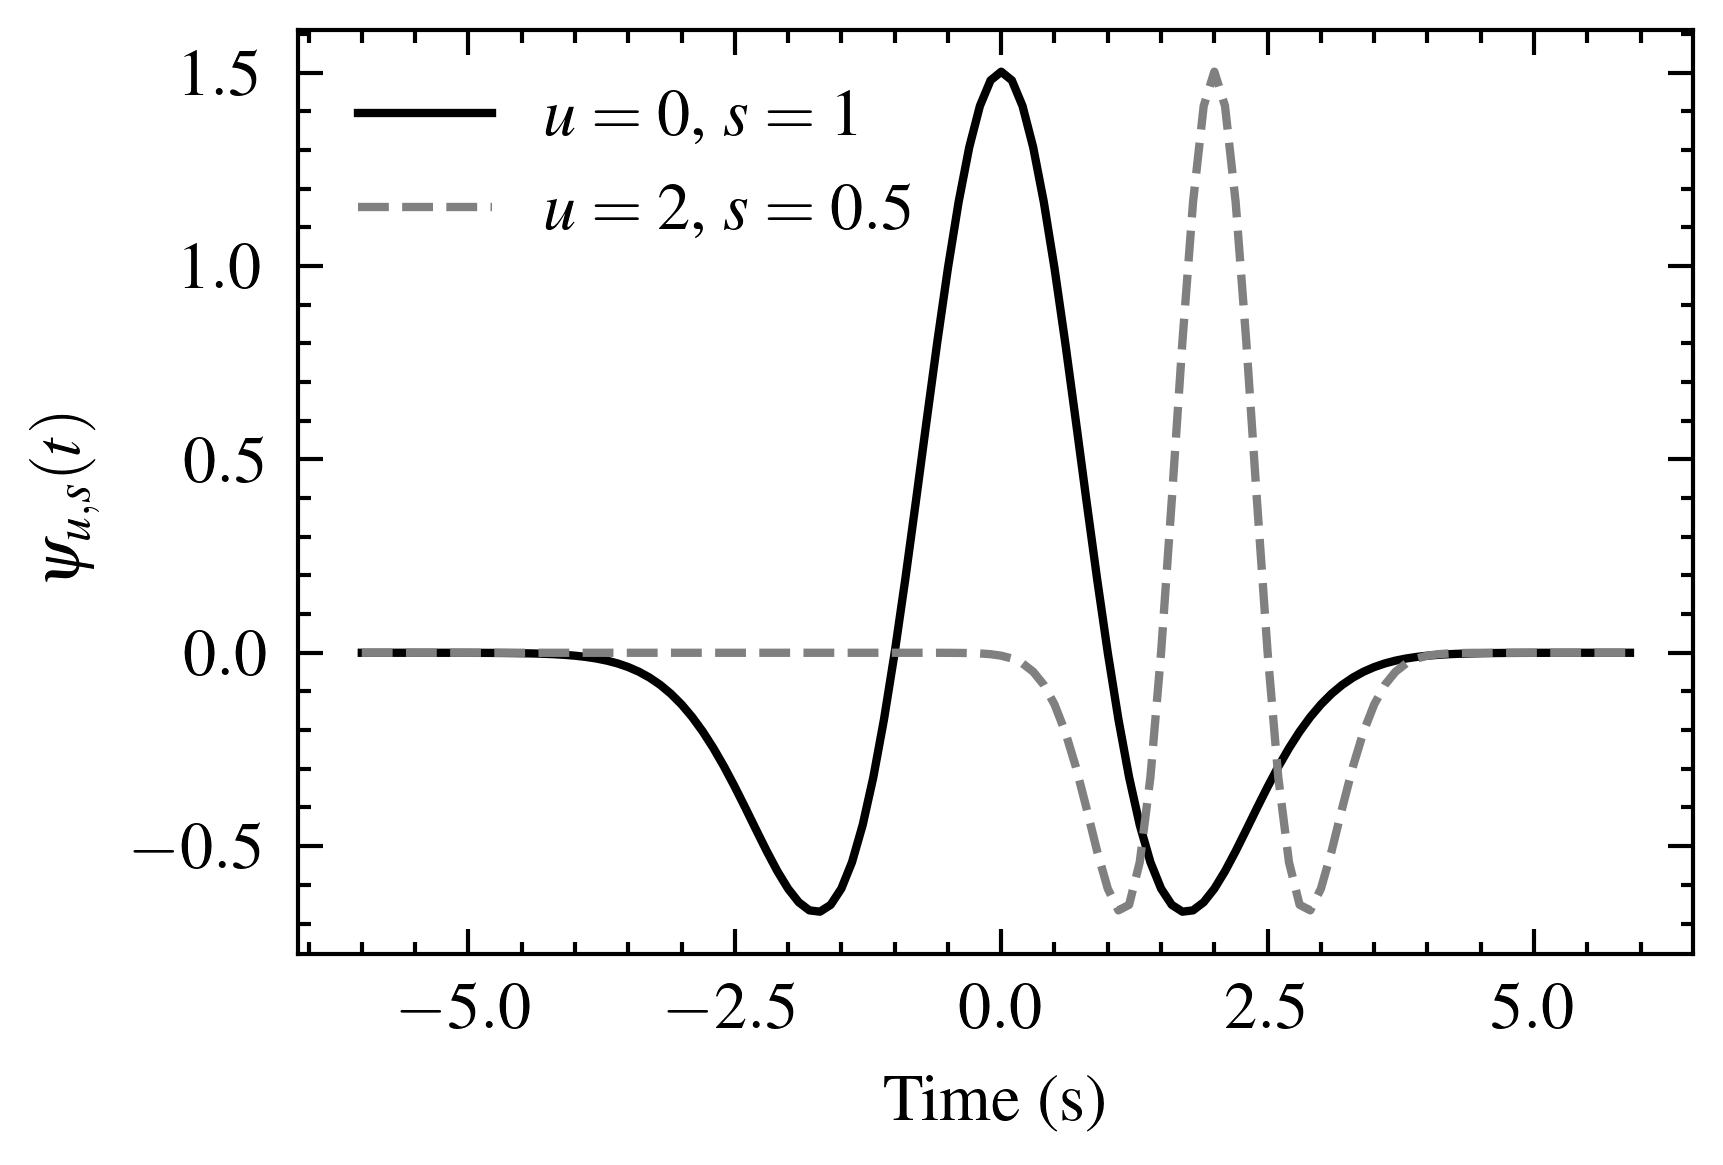

In [9]:
plt.figure(figsize=(3,2))
plt.plot(m_t, m)
plt.plot(m_t, m_us, color="gray")
plt.xlabel("Time (s)")
plt.ylabel("$\psi_{u,s}(t)$")
plt.legend(["$u=0$, $s=1$", "$u=2$, $s=0.5$"])
plt.savefig(f"figures_wavelet/mexican_hat.png", dpi=300)

In [10]:
scales = np.arange(0.1, 32, 0.1)
w, _ = pywt.cwt(x, scales, 'mexh')

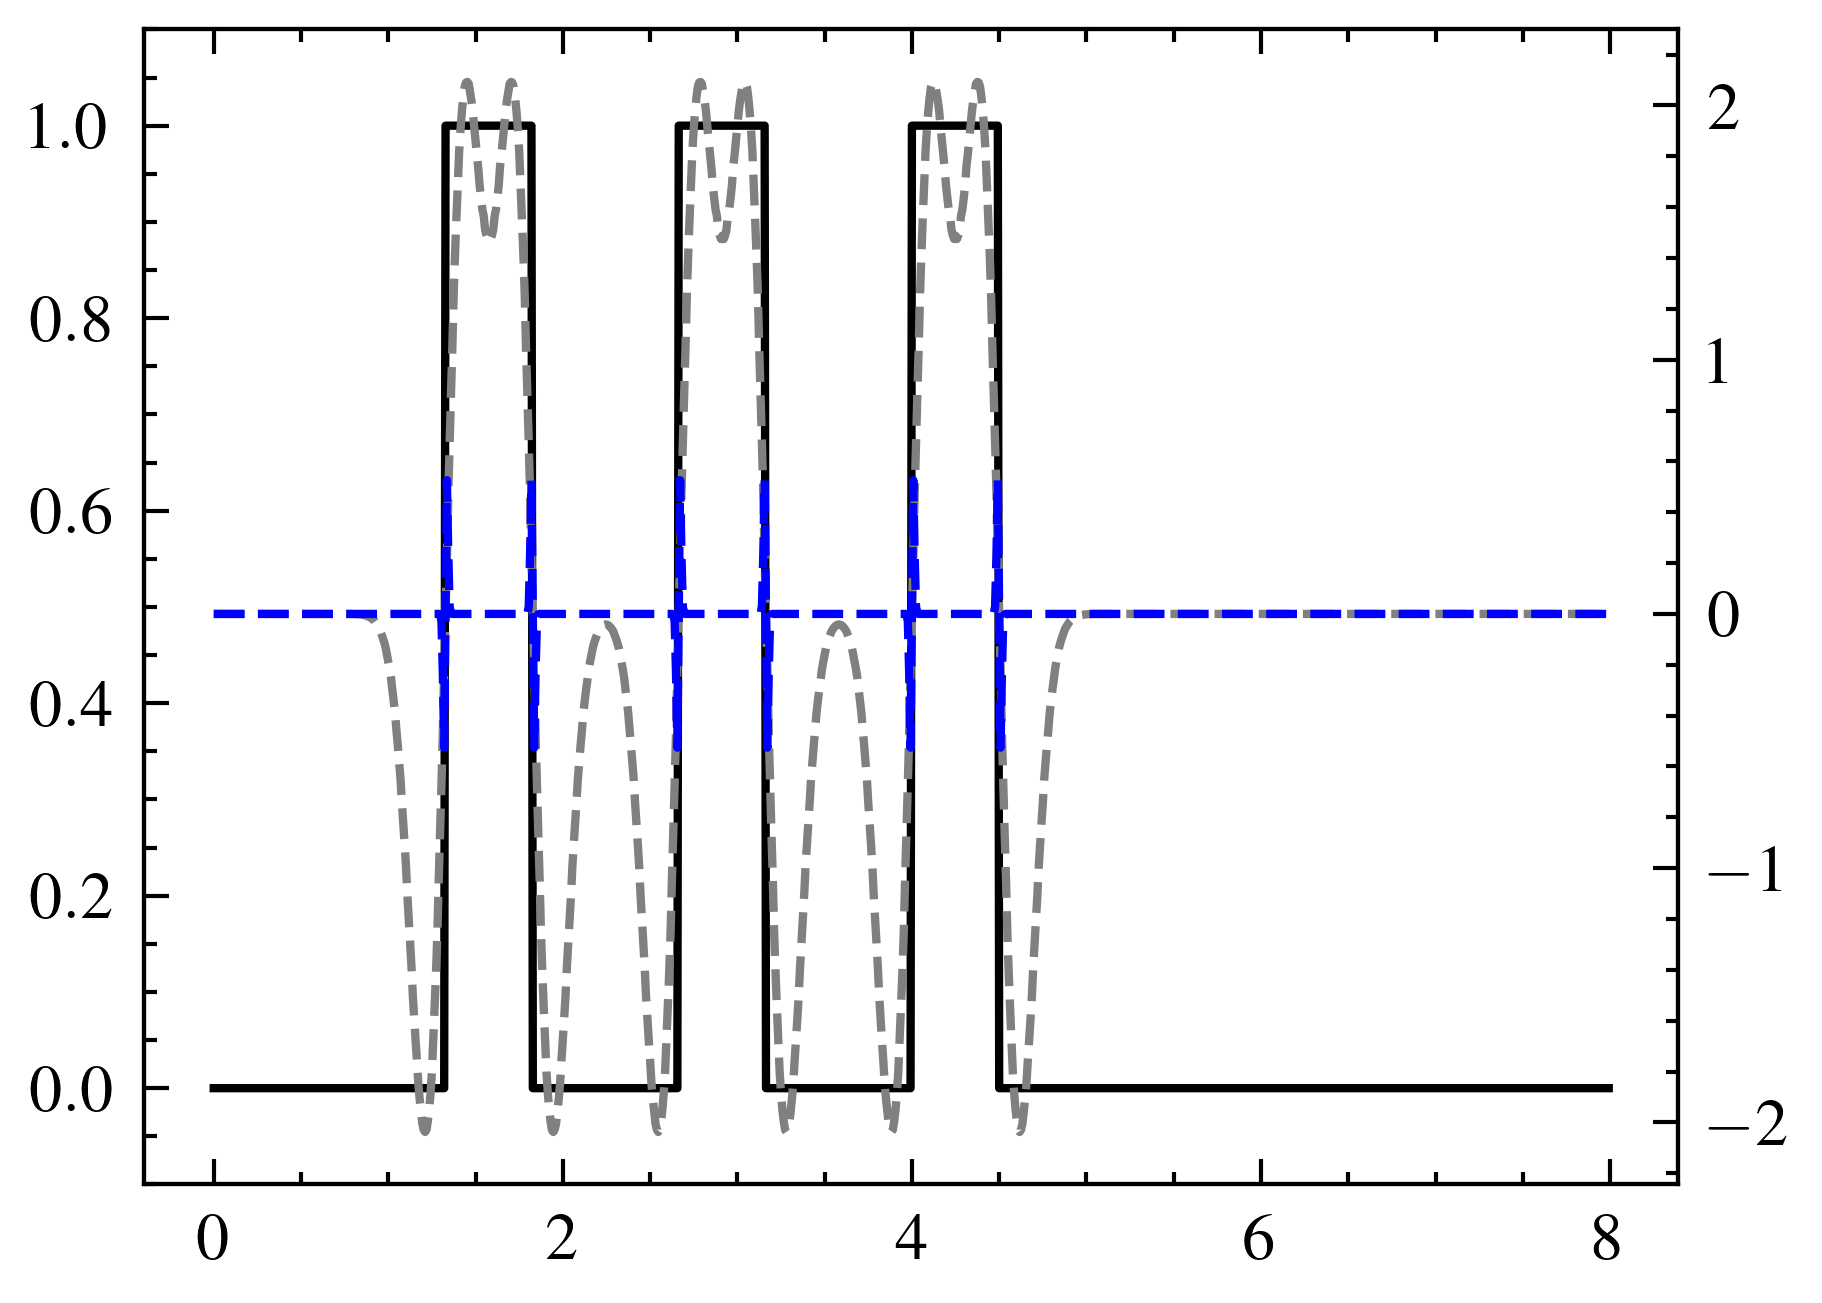

In [11]:
fig = plt.figure()
ax = fig.add_subplot()
ax.plot(t, x, color="k", linestyle="-")
ax.set_ylim([-0.1,1.1])
ax2 = ax.twinx()

scale = 15
idx = np.argmin(np.abs(scales - scale))
ax2.plot(t, w[idx], color="gray", linestyle="--")

scale = 1
idx = np.argmin(np.abs(scales - scale))
ax2.plot(t, w[idx], color="blue", linestyle="--")


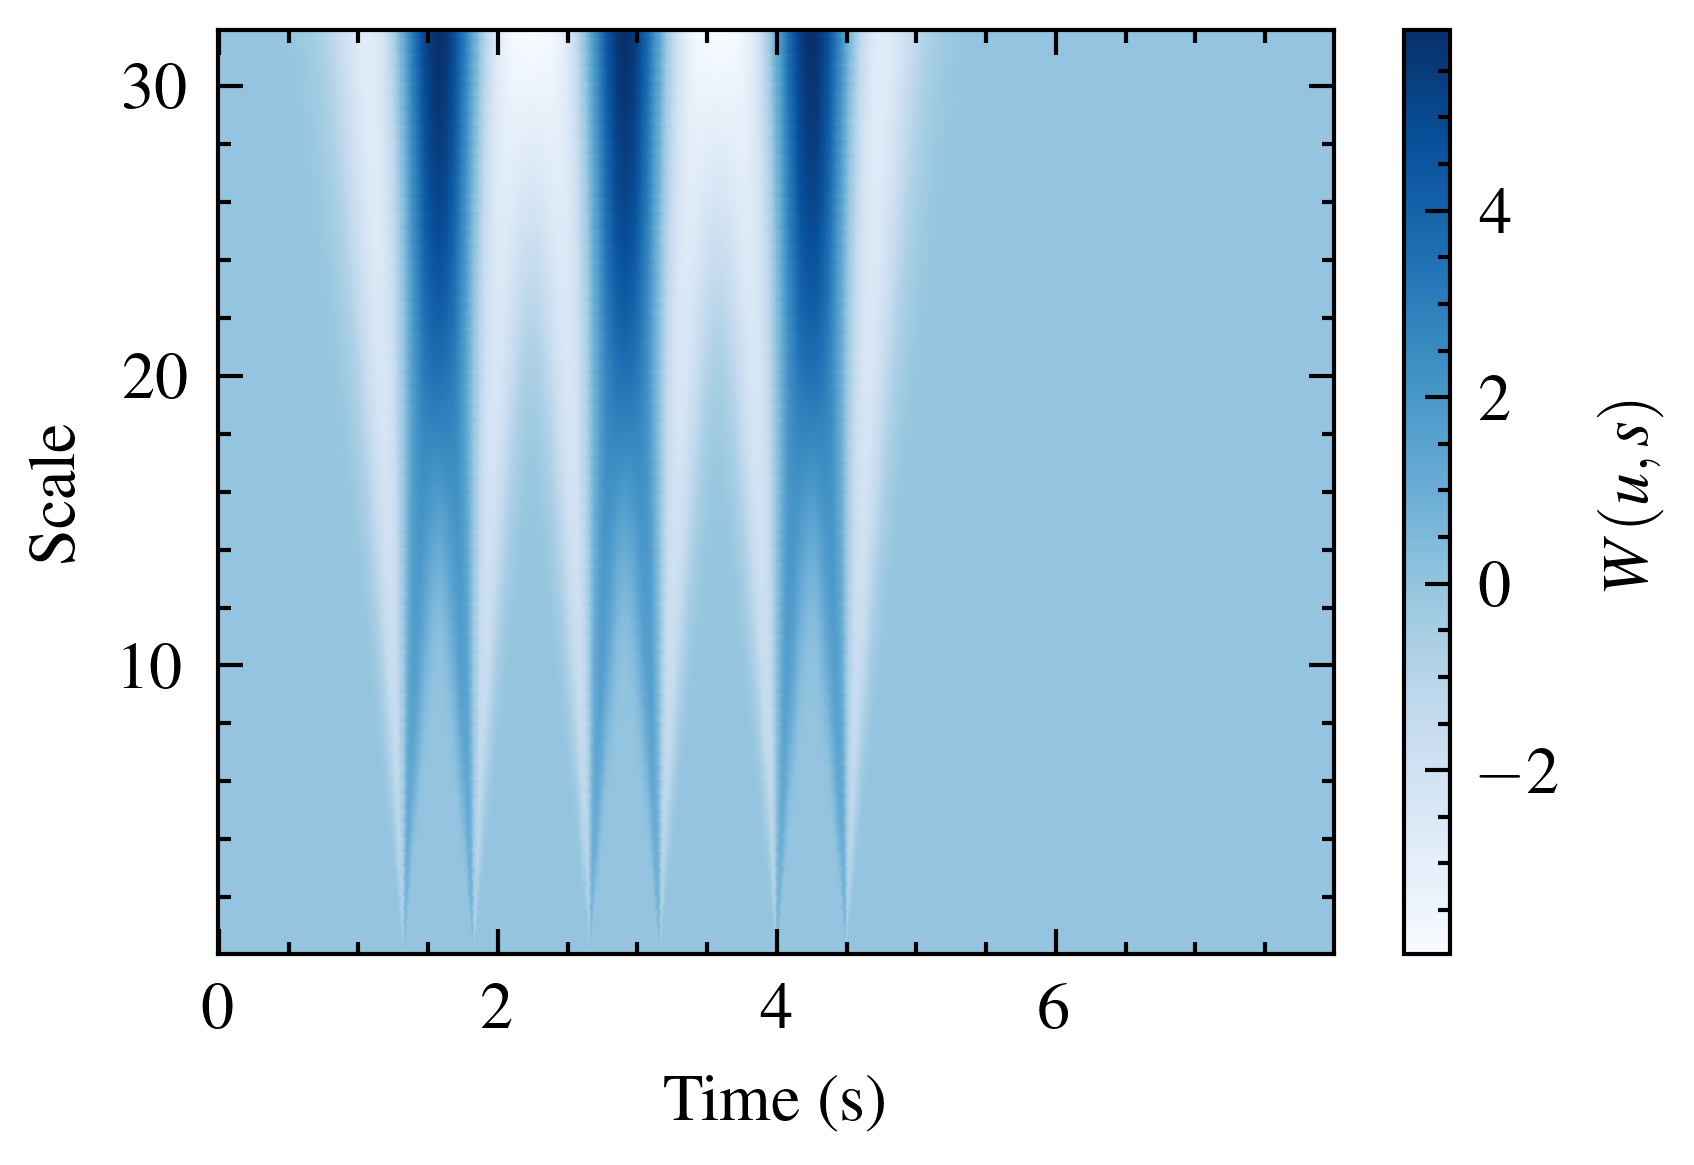

In [12]:
plt.figure(figsize=(3,2))
plt.pcolormesh(t, scales, w, cmap="Blues")
plt.colorbar(label="$W(u,s)$")
plt.xlabel("Time (s)")
plt.ylabel("Scale")
plt.savefig(f"figures_wavelet/example_cwt.png", dpi=300)

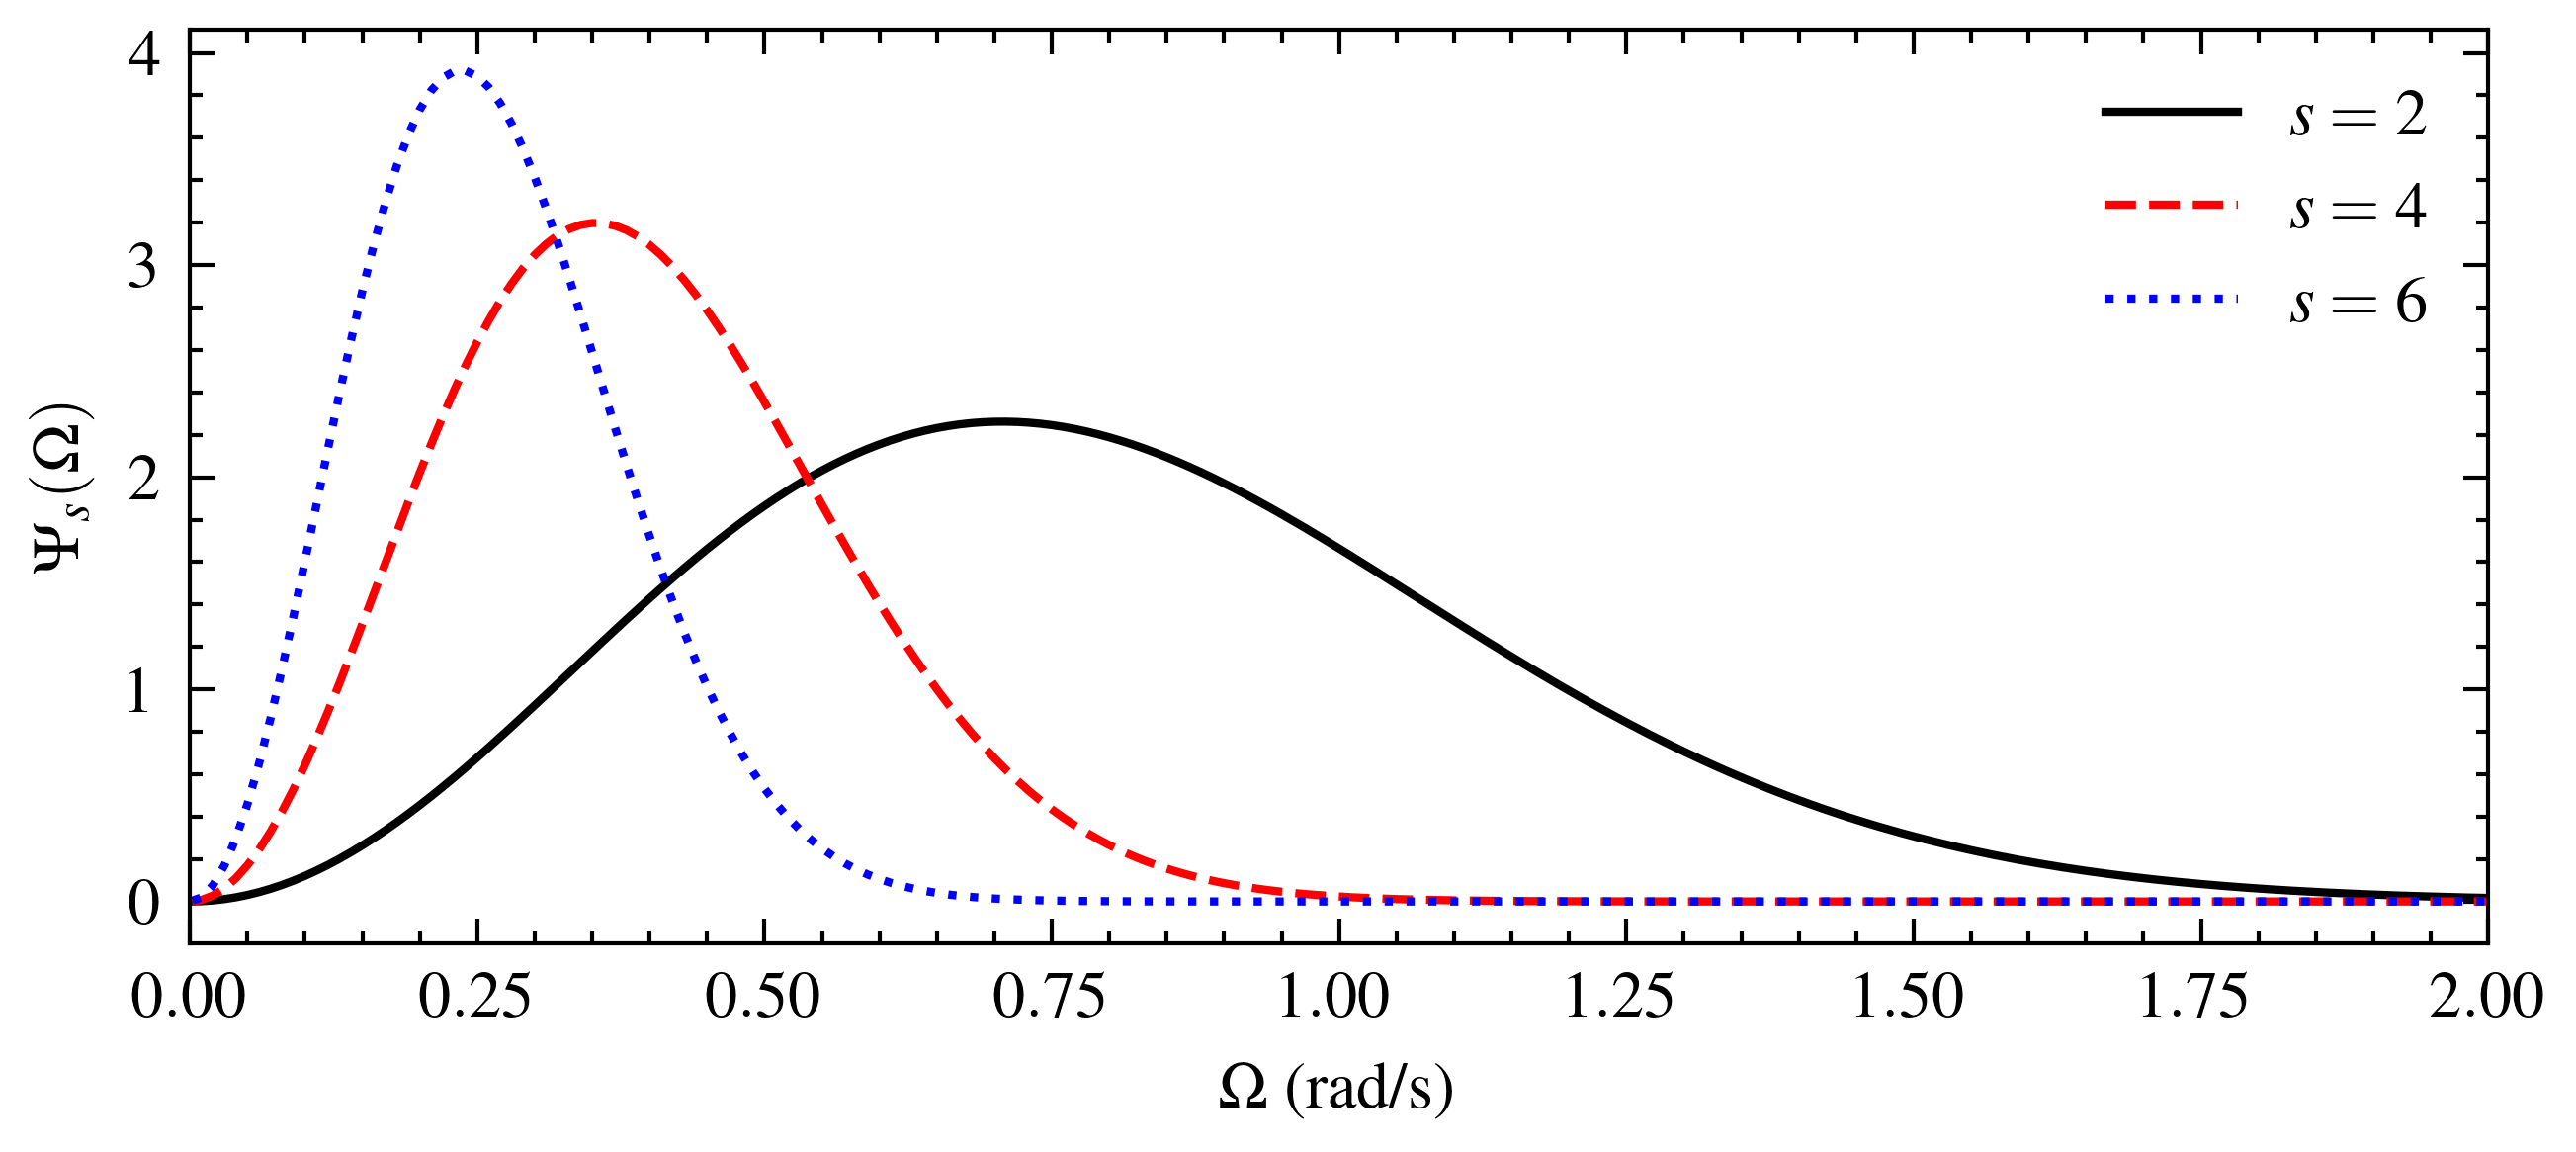

In [22]:
plt.figure(figsize=(5,2))
w = np.arange(-5, 5, 0.01)
labels = []
for s in range(2, 8, 2):
    mw = [np.sqrt(s) * mexhat_psi_freq(s*ww) for ww in w]
    plt.plot(w, np.abs(mw))
    labels.append("$s="+str(s)+"$")
plt.xlim([0, 2])
plt.legend(labels)
plt.xlabel("$\Omega$ (rad/s)")
plt.ylabel("$\Psi_s(\Omega)$");
plt.savefig(f"figures_wavelet/mexican_hat_freq.png", dpi=300)

# DWT

In [14]:
coefs = pywt.wavedec(x, wavelet="haar")

In [15]:
dwt_coefs_raw = np.abs(np.hstack(coefs))
dwt_coefs_sorted = np.sort(dwt_coefs_raw)[::-1]

dft_coefs_complex = np.fft.rfft(x)[1:]
dft_coefs_real = np.abs(np.real(dft_coefs_complex))
dft_coefs_imag = np.abs(np.imag(dft_coefs_complex))
dft_coefs = np.abs(np.hstack((dft_coefs_real, dft_coefs_imag)))
dft_coefs_sorted = np.sort(dft_coefs)[::-1]

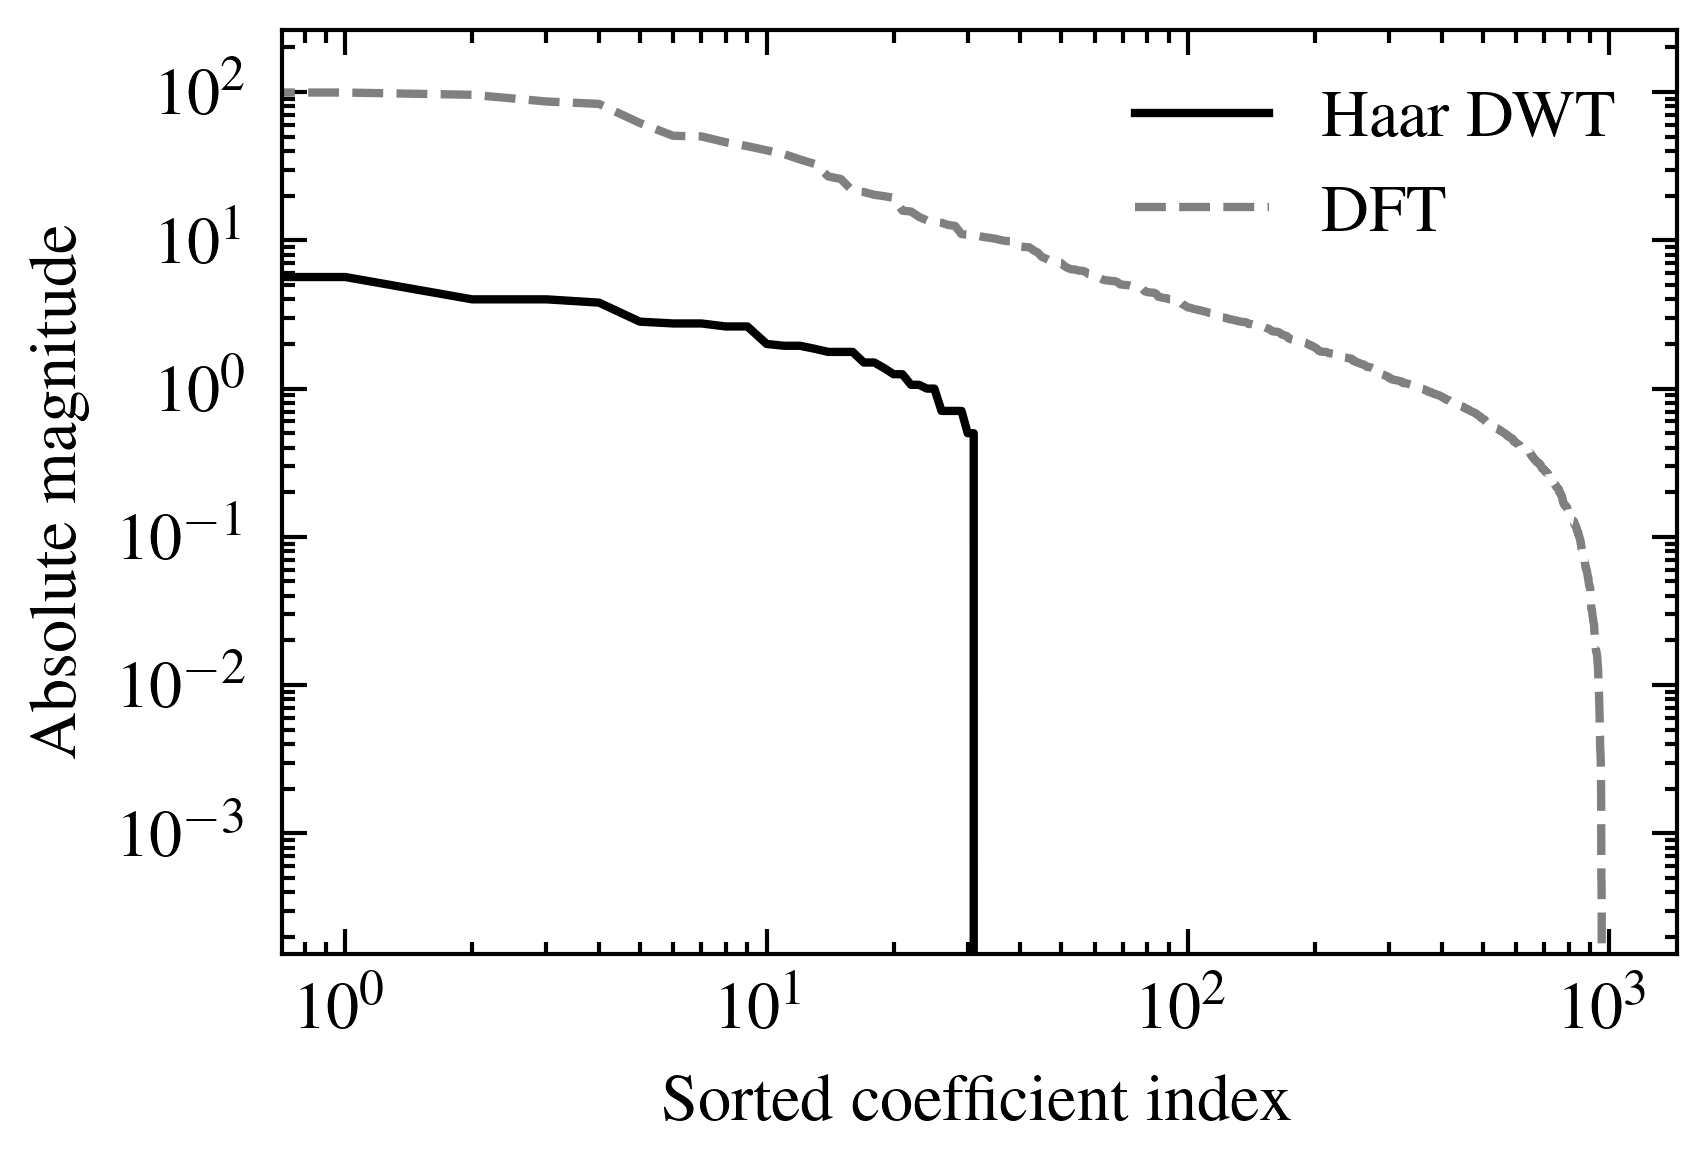

In [16]:
fig = plt.figure(figsize=(3,2))
ax = fig.add_subplot()

ax.plot([], color="k", linestyle="-")
ax.plot([], color="gray", linestyle="--")
plt.legend(["Haar DWT", "DFT"])

ax.set_xscale("log")
ax.set_yscale("log")
ax.plot(dwt_coefs_sorted, color="k")
ax.set_ylabel("Absolute magnitude")
#ax2 = ax.twinx()
#ax2.set_yscale("log")
ax.plot(dft_coefs_sorted, color="gray", linestyle="--")
#ax2.set_ylabel("DFT coefficient magnitude")
ax.set_xlabel("Sorted coefficient index")
#ax.set_yticks([1, 10])
plt.savefig(f"figures_wavelet/example_dwt_indexes.png", dpi=300)

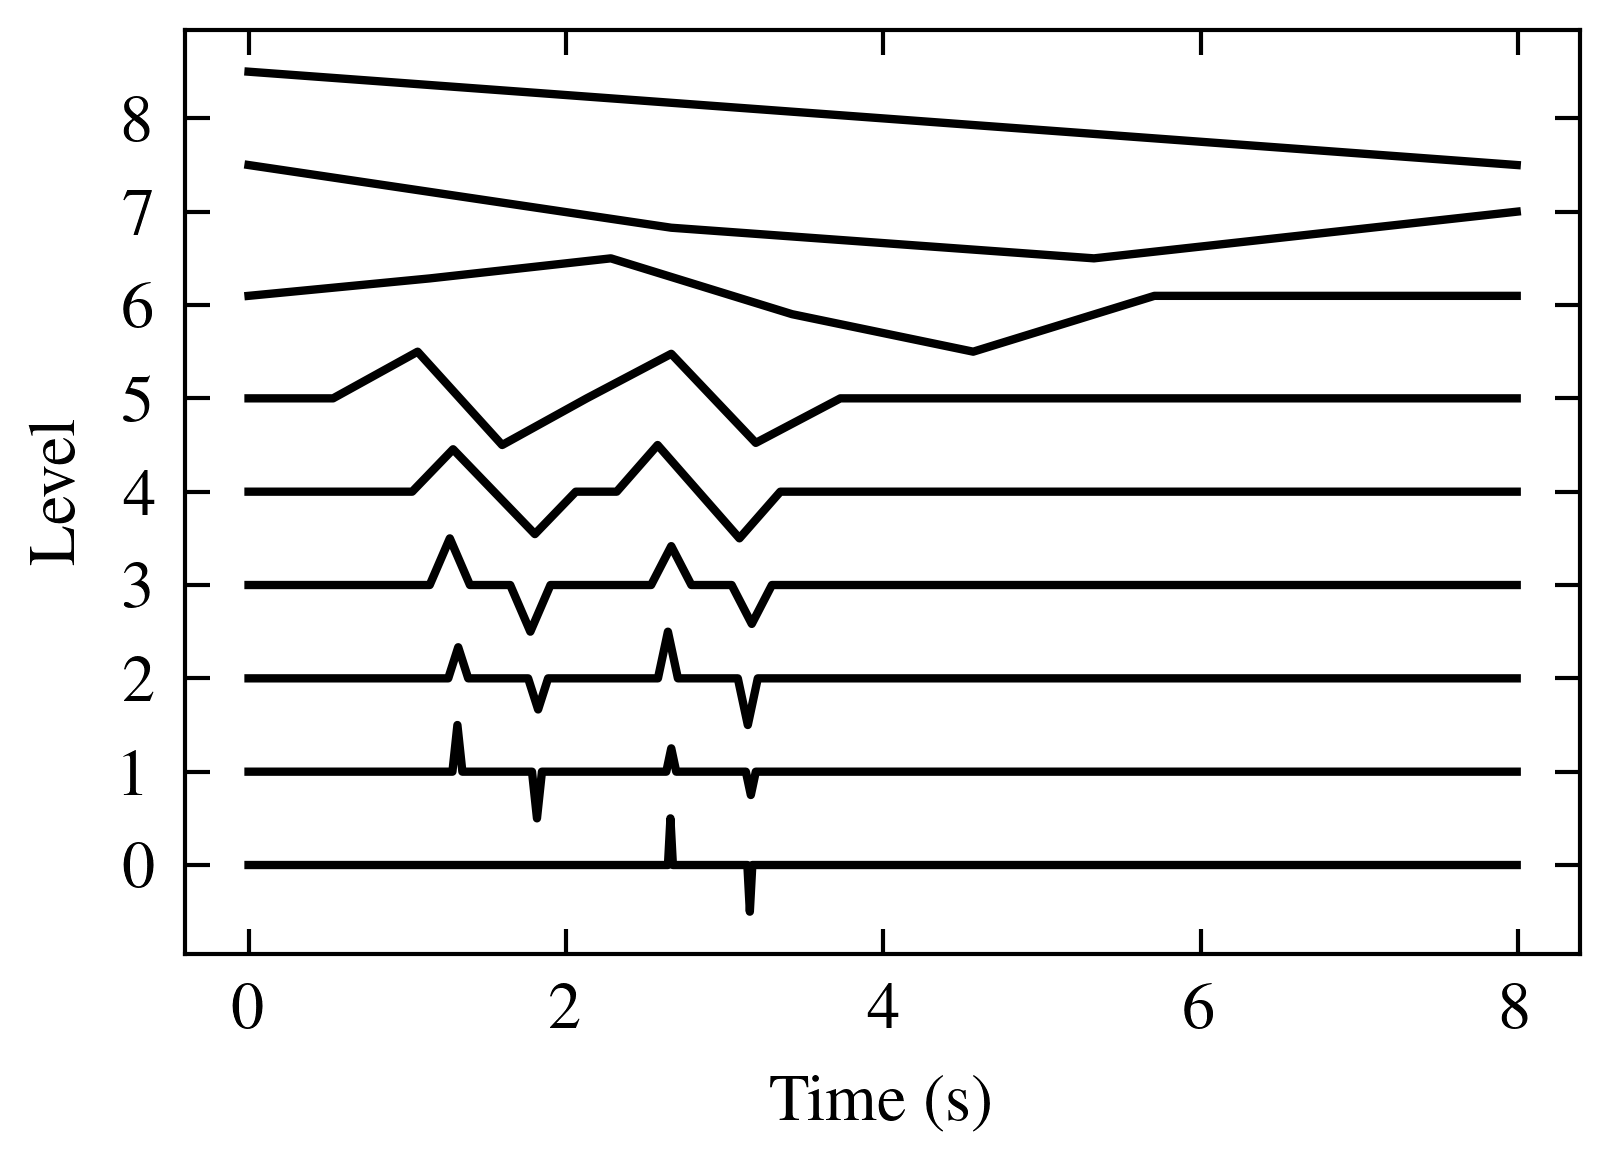

In [17]:
plt.figure(figsize=(3,2))
t_max = t[-1]
t_min = t[0]
levels = []
for l, coef in enumerate(coefs):
    c = np.array(coef)
    new_l = 10 - l
    if len(c) > 1:
        c = (c - c.max()) / (c.min() - c.max())
    else:
        continue
    t_temp = np.linspace(t_min, t_max, len(c))
    plt.plot(t_temp, c+new_l-0.5, color="k", linestyle="-")
    levels.append(new_l)
levels = np.array(levels)
plt.minorticks_off()
plt.yticks(levels);
plt.ylabel("Level");
plt.xlabel("Time (s)");
plt.savefig(f"figures_wavelet/example_dwt_1d.png", dpi=300)

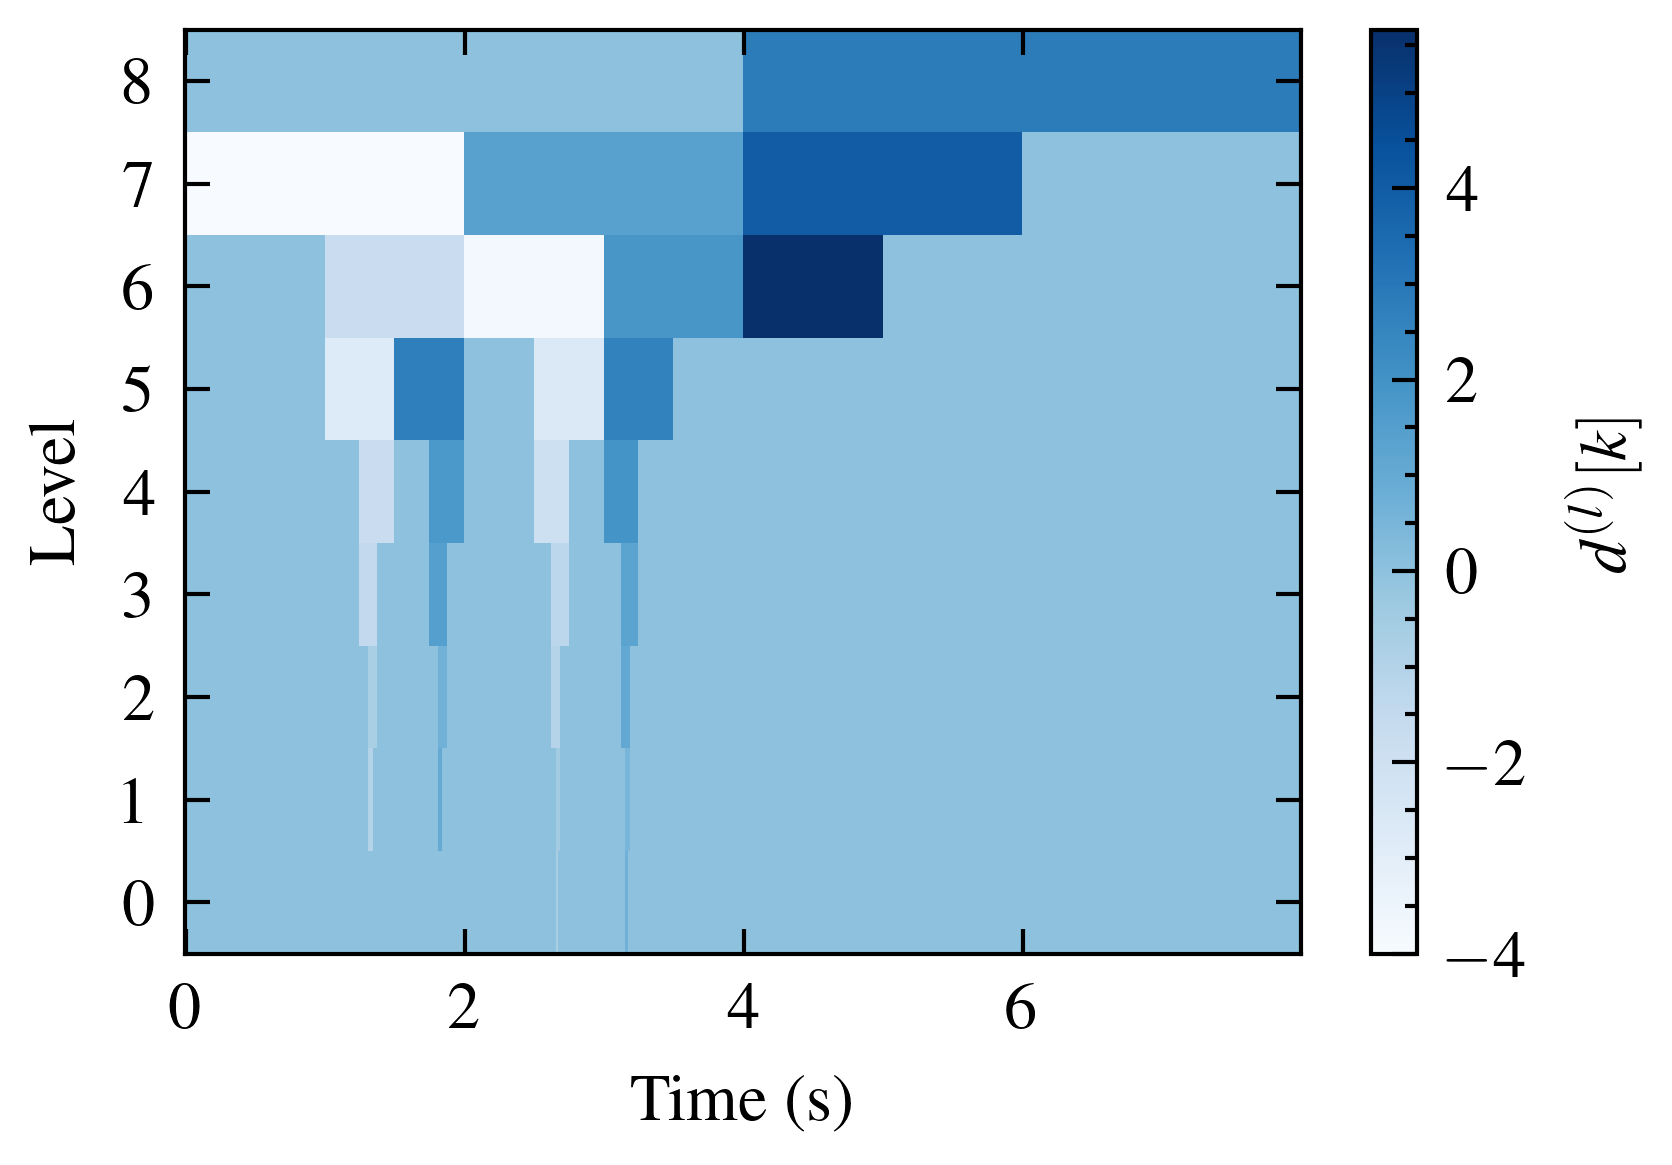

In [18]:
N = len(x)
a = []
levels = []
for l, coef in enumerate(coefs):
    if isinstance(coef, float) or len(coef)==1:
        continue
    levels.append(l-2)
    n = len(coef)
    if n==N:
        a.append(np.array(coef))
    else:
        a.append(np.hstack([[c]*(N//n) for c in coef]))
levels = np.array(levels)[::-1]

fig = plt.figure(figsize=(3,2))
ax = fig.add_subplot()
m = ax.pcolormesh(t, levels, np.array(a), cmap="Blues")
plt.colorbar(m, label="$d^{(l)}[k]$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Level")
ax.set_yticks(levels, levels);
ax.minorticks_off()
plt.savefig(f"figures_wavelet/example_dwt.png", dpi=300)

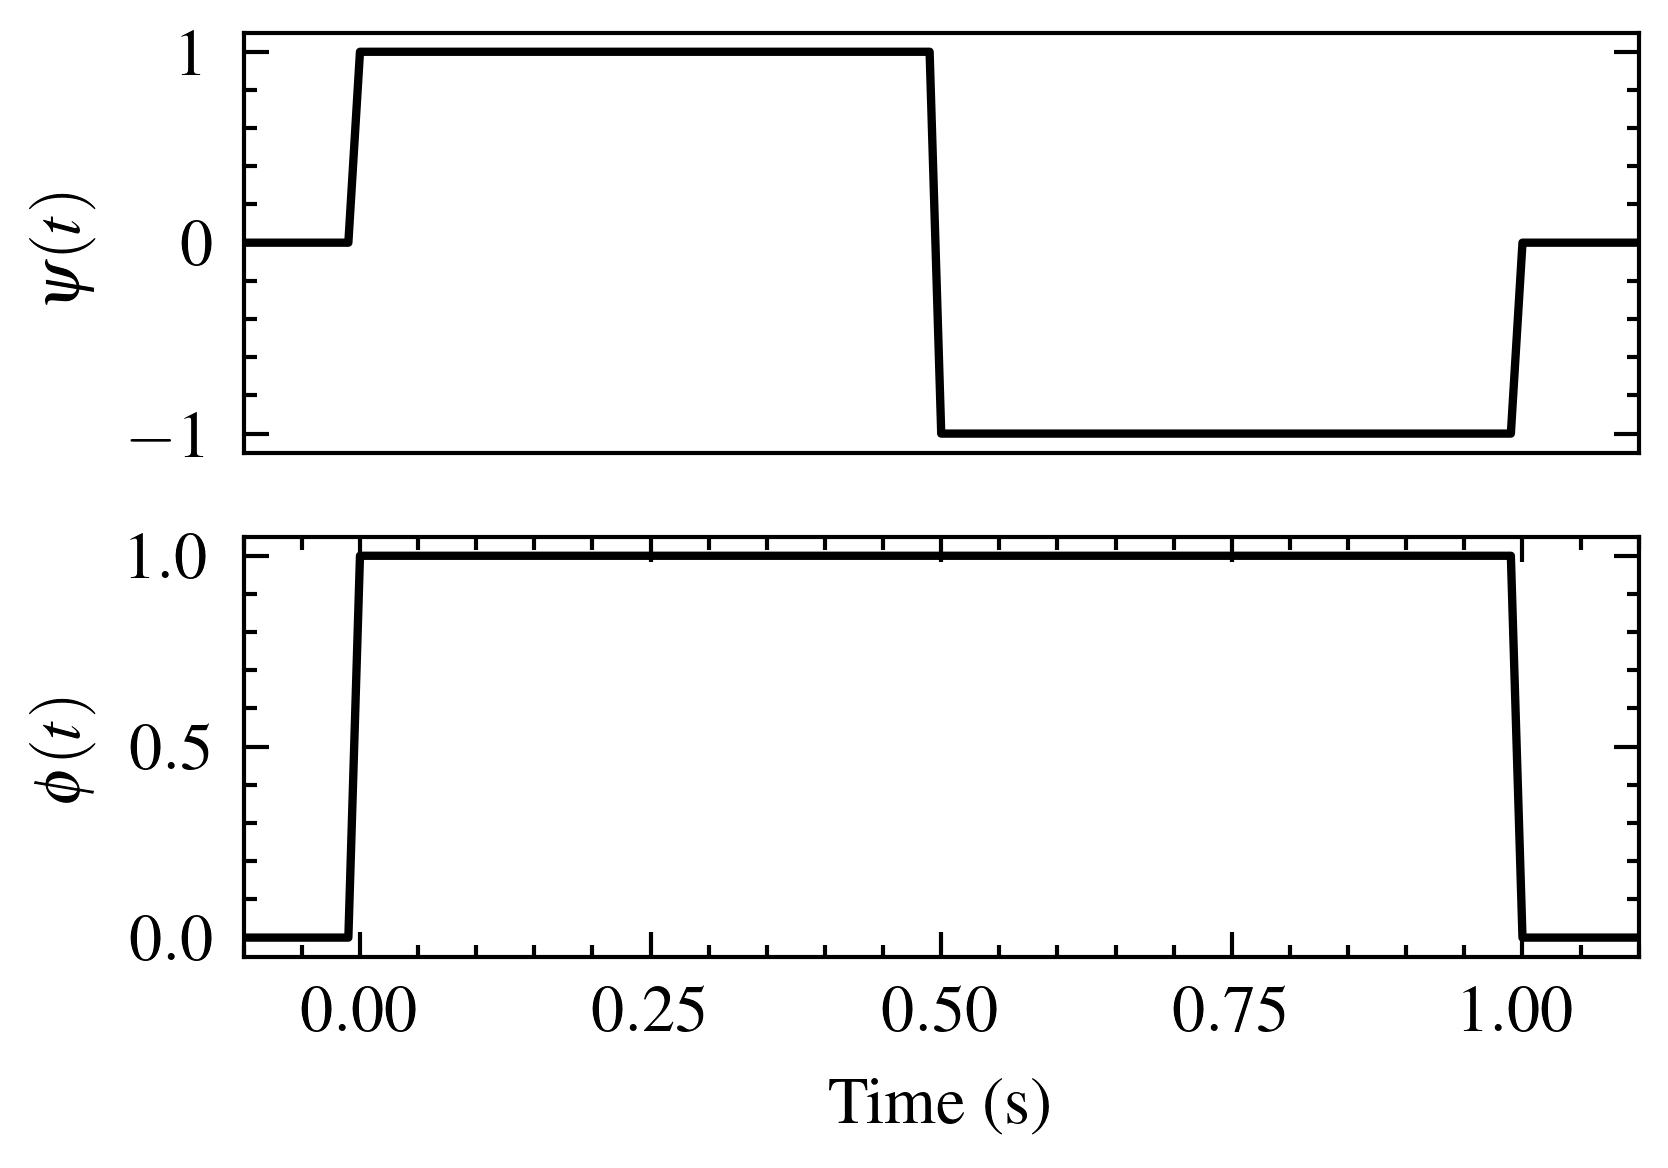

In [19]:
t = np.arange(-1.5, 1.5, 0.01)
haar_wav = np.zeros_like(t)
haar_wav[t<0.5] = 1
haar_wav[t>0.5] = -1
haar_wav[t>1] = 0
haar_wav[t<0] = 0

haar_sc = np.ones_like(t)
haar_sc[t>1] = 0
haar_sc[t<0] = 0

fig = plt.figure(figsize=(3,2))
ax1 = fig.add_subplot(211)
ax1.plot(t, haar_wav)
ax1.set_xticks([])
ax1.set_xlim([-0.1, 1.1])
ax1.set_ylabel("$\psi(t)$")

ax2 = fig.add_subplot(212)#, sharex = ax1)
ax2.plot(t, haar_sc)
ax2.set_xlim([-0.1, 1.1])
ax2.set_ylabel("$\phi(t)$")
ax2.set_xlabel("Time (s)")

plt.savefig(f"figures_wavelet/haar.png", dpi=300)

# Wavelet functions

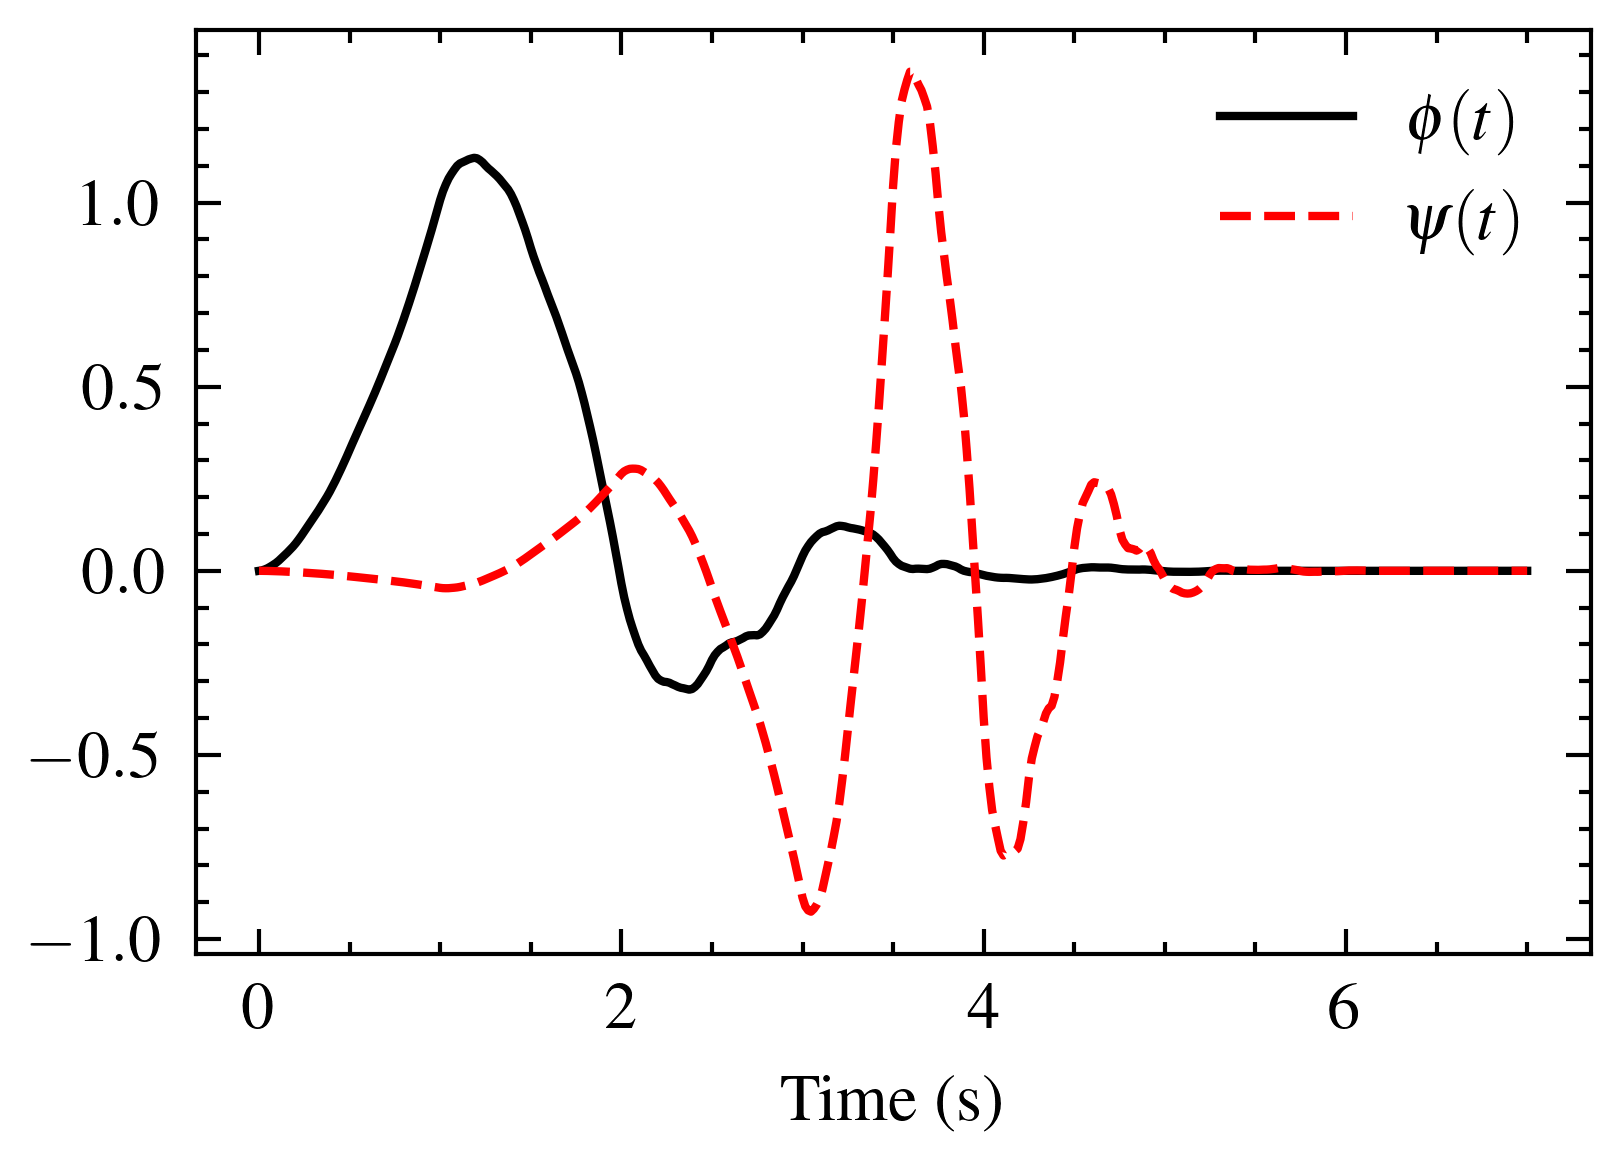

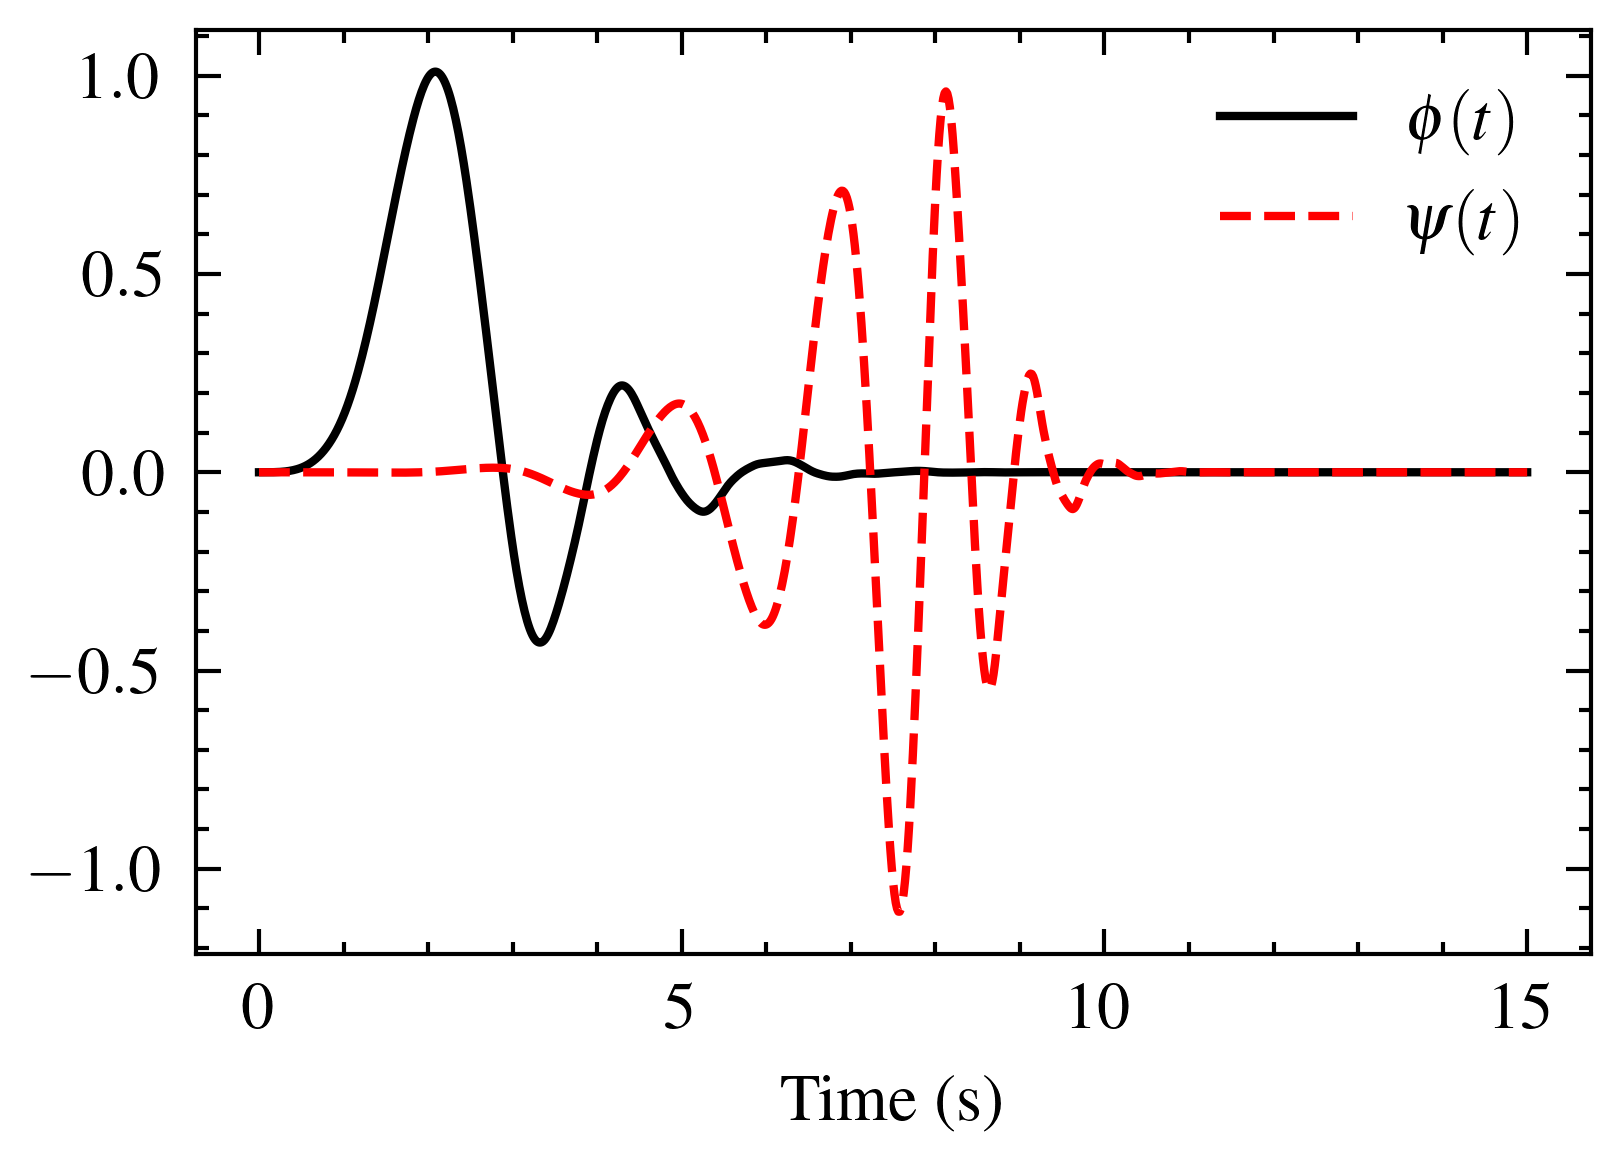

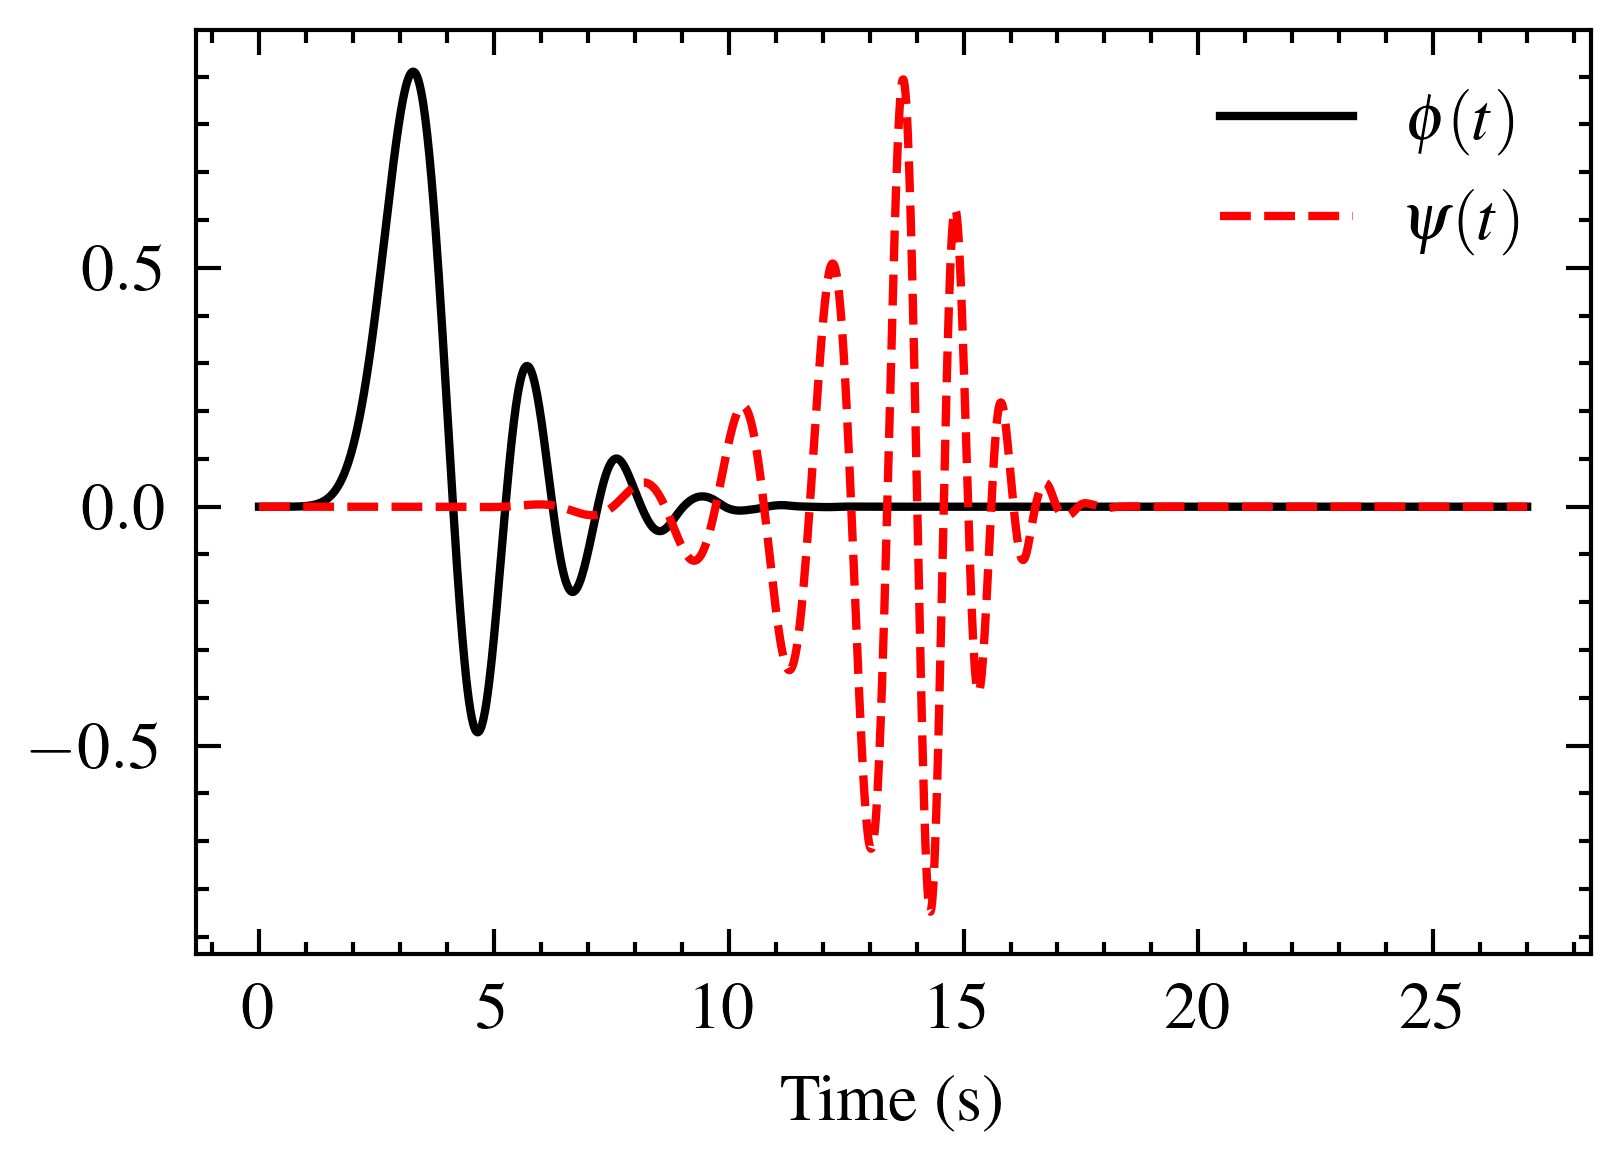

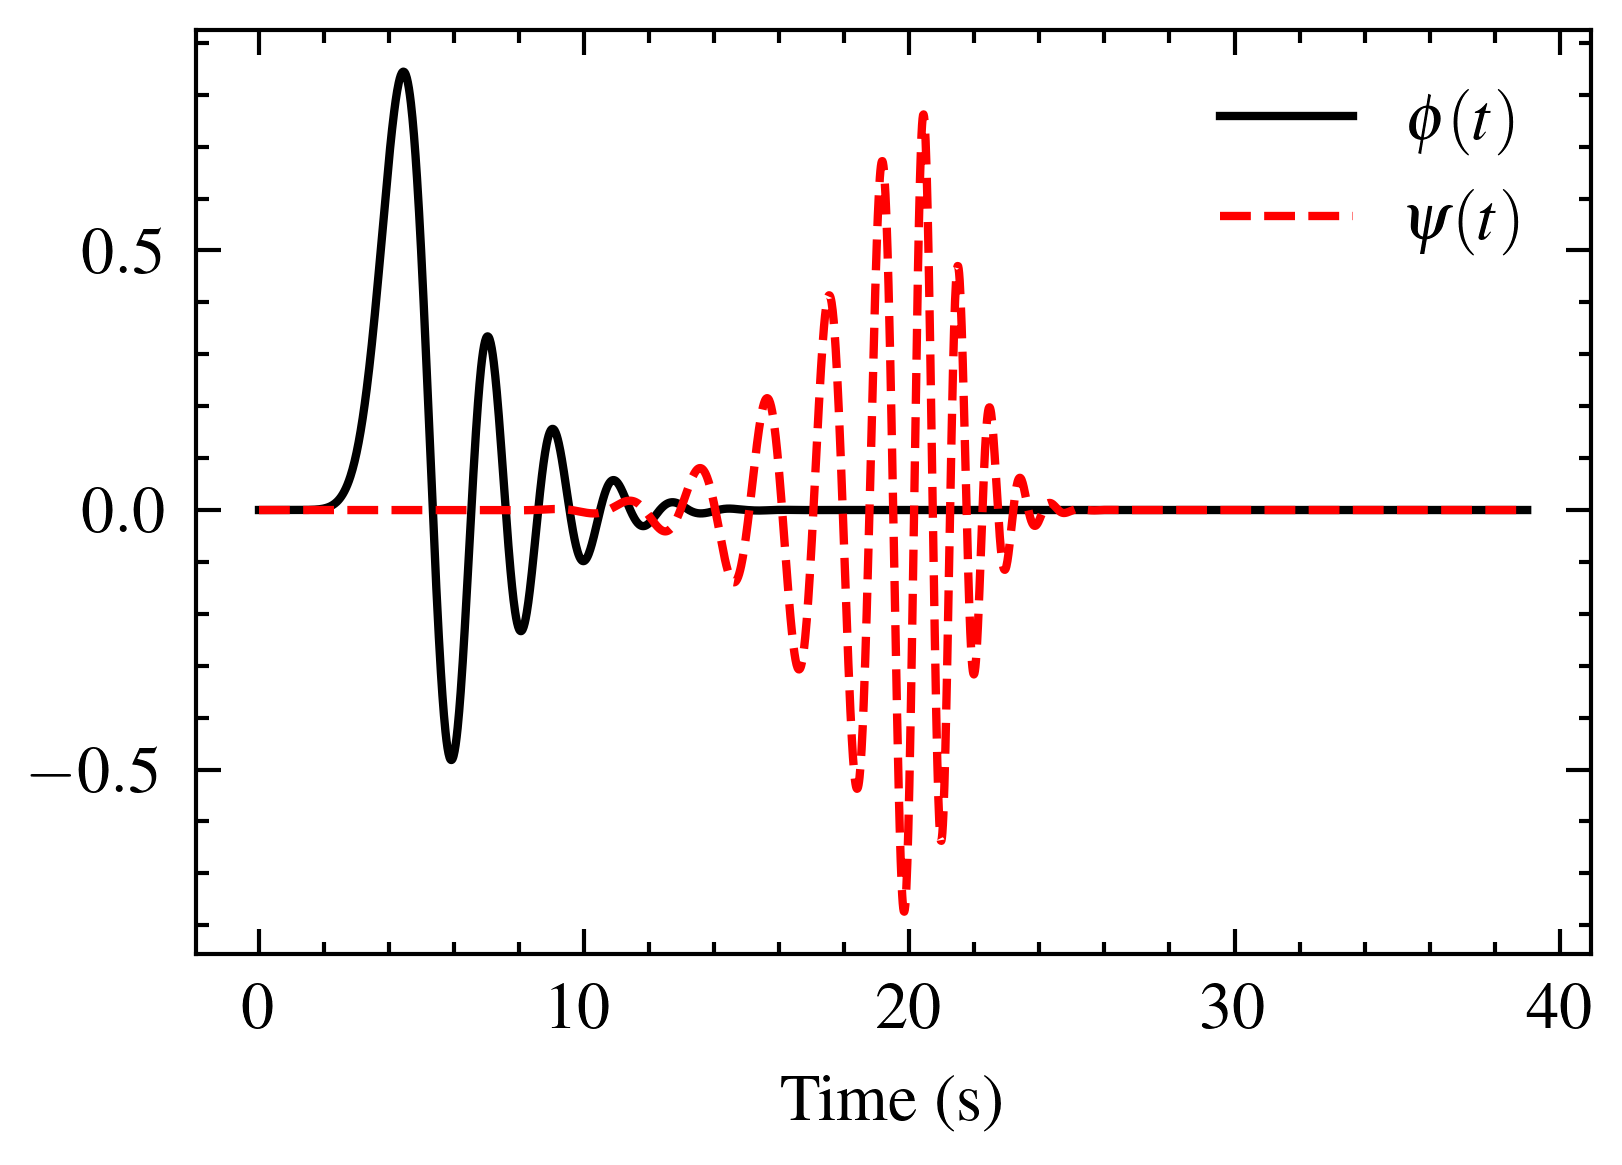

In [20]:
funcs = ["db4", "db8", "db14", "db20"]
for f in funcs:
    fi = int(f.replace("db", ""))
    wavelet = pywt.Wavelet(f)
    phi, psi, x = wavelet.wavefun(level=6)
    plt.figure(figsize=(3,2))
    plt.plot(x, phi)
    plt.plot(x, psi)
    plt.xlabel("Time (s)")
    plt.legend(["$\phi(t)$", "$\psi(t)$"])
    plt.savefig(f"figures_wavelet/db{fi}.png", dpi=300)